В этом файле мы будем улучшать метрики наших бейслайн моделей, будем проверять несколько гипотез:

1) Убрать или ослабить макроэкономические признаки, может тогда модель будет лучше ранжировать объекты 
2) Сбалансировать классы через class_weight и SMOTE
3) StandartScaler для числовых признаков, может тогда логрег покажет метрики лучше 
4) Feature engineering на стационарных признаках клиента (не на макроэкономических признаках)

In [60]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [61]:
import numpy as np, pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from helper import load_clean_data, get_preprocessor, evaluate_models_cv, get_preprocessor_with_exclude, get_preprocessor_scaled
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

SEED = 42

In [62]:
df = load_clean_data()
X, y = df.drop(columns=["y"]), df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
tscv = TimeSeriesSplit(5)

models = [
    ("logreg", LogisticRegression(random_state=SEED, max_iter=1000, solver="liblinear")),
    ("tree", DecisionTreeClassifier(random_state=SEED)),
    ("forest", RandomForestClassifier(random_state=SEED)),
    ("lgbm", LGBMClassifier(random_state=SEED, verbose=-1)),
]

In [63]:
# Здесь наша точка отсчета - baseline по CV

initial_metrics = evaluate_models_cv(models, X_train, y_train, get_preprocessor(), tscv)
initial_metrics

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

,roc_auc,f1_macro,precision_macro,recall_macro,accuracy
logreg,0.530876,0.480799,0.463366,0.500000,0.926733
tree,0.501840,0.500045,0.502751,0.501580,0.858568
forest,0.498786,0.481208,0.480032,0.499918,0.926047
lgbm,0.502597,0.480659,0.463353,0.499719,0.926200


1) Убрать или ослабить макроэкономические признаки, может тогда модель будет лучше ранжировать объекты 

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

<Axes: >

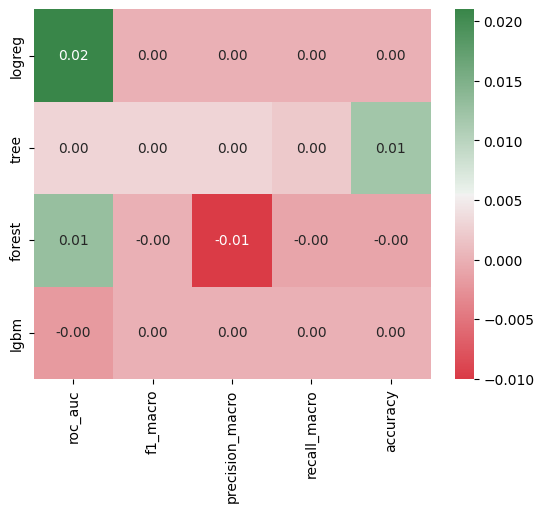

In [64]:
macro = ["euribor3m", "nr.employed", "emp.var.rate", "cons.price.idx", "cons.conf.idx"]

X_no_macro = X_train.drop(columns=macro)
no_macro_metrics = evaluate_models_cv(models, X_no_macro, y_train, get_preprocessor_with_exclude(exclude=macro), tscv)

delta = (no_macro_metrics - initial_metrics).round(3)

my_cmap = sns.diverging_palette(10, 133, as_cmap=True)
sns.heatmap(data = delta, annot=True, fmt = ".2f", cmap = my_cmap)

Как видим дельта везде копейки, которую можно списать на шум. Копейки, сущие копейки 

ВЫВОД:
Предсказательная мощь датасета сосредоточена в нестационарных макропризнаках, которые не переносятся на будущие периоды. Поэтому честная оценка качества во времени ограничена. Получается бейслайн не был случайностью

2) Сбалансировать классы через class_weight и SMOTE

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/si

<Axes: >

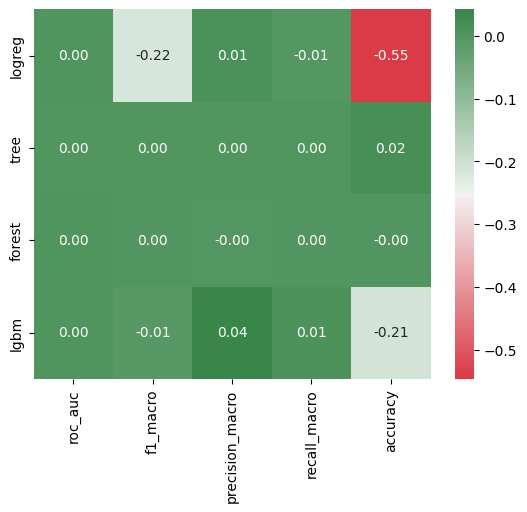

In [65]:
models_balanced = [
    ("logreg", LogisticRegression(random_state=SEED, max_iter=1000, solver="liblinear", class_weight="balanced")),
    ("tree", DecisionTreeClassifier(random_state=SEED, class_weight="balanced")),
    ("forest", RandomForestClassifier(random_state=SEED, class_weight="balanced")),
    ("lgbm", LGBMClassifier(random_state=SEED, verbose=-1, class_weight="balanced")),
]

balanced_metrics = evaluate_models_cv(models_balanced, X_train, y_train, get_preprocessor(), tscv)

delta = (balanced_metrics - initial_metrics).round(3)
sns.heatmap(data = delta, annot=True, fmt = ".2f", cmap = my_cmap)


Прироста почти нигде нет, разве что есть только сильное падение accuracy у логрега и бустинга

Теперь пробуем SMOTE

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer AP

<Axes: >

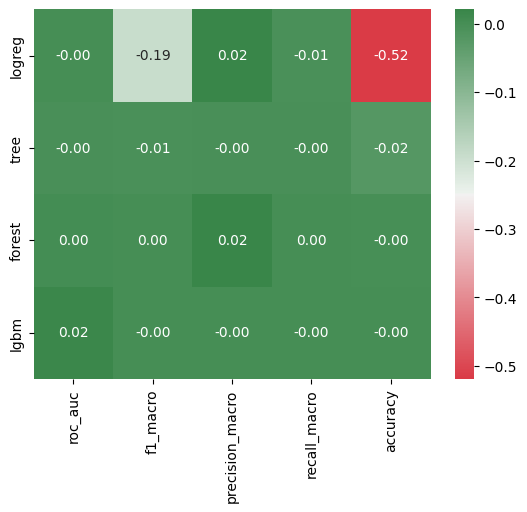

In [66]:
smote_metrics = evaluate_models_cv(models, X_train, y_train, get_preprocessor(), tscv, sampler=SMOTE(random_state=SEED))

delta = (smote_metrics - initial_metrics).round(3)
sns.heatmap(data=delta, annot=True, fmt=".2f", cmap=my_cmap)

ВЫВОД:

По сути вывод тот же, предсказательный сигнал сидит в макроэкономических признаках, которые не переносятся на будущие периоды. Ни удаление макро, ни балансировка не фиксят это, потому что: убрать макро => убрать сам сигнал, балансировать => не улучшает метрики f1/precision/recall и уж тем более не улучшает способность ранжировать объекты. По всей видимости ROC-AUC = 0.5 это фундаментальное свойство задачи, а не ошибка

3) StandartScaler для числовых признаков, может тогда логрег покажет метрики лучше 

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

<Axes: >

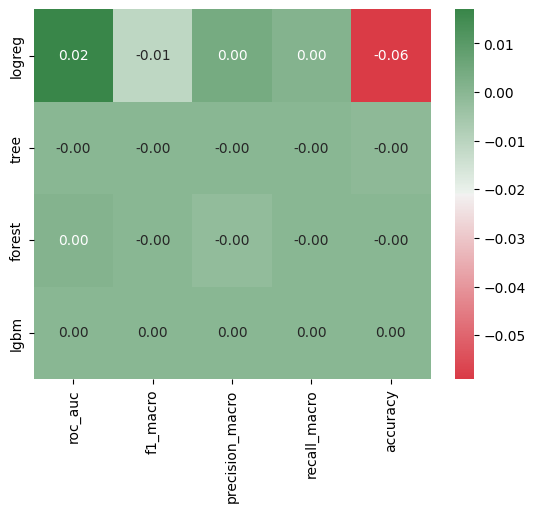

In [67]:
scaled_metrics = evaluate_models_cv(models, X_train, y_train, get_preprocessor_scaled(), tscv)

delta = (scaled_metrics - initial_metrics).round(3)

sns.heatmap(data = delta, annot=True, fmt=".2f", cmap=my_cmap)

ВЫВОД:
Небольшой прирост ROC-AUC для логрега погоды не меняет, в целом изменений нет из-за проблем, описанных выше

4) Feature engineering

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

<Axes: >

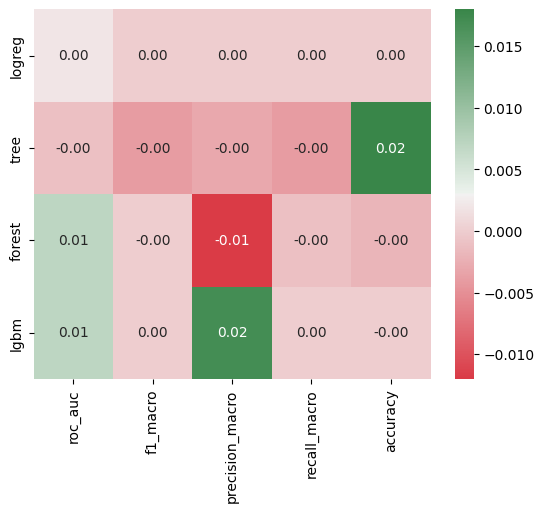

In [68]:
X_age_bin = X_train.copy()

X_age_bin["age"] = pd.cut(X_age_bin["age"], bins=[0, 30, 45, 60, 120], labels=False)

age_bin_metrics = evaluate_models_cv(models, X_age_bin, y_train, get_preprocessor(), tscv)

delta = (age_bin_metrics - initial_metrics).round(3)
sns.heatmap(data=delta, annot=True, fmt=".2f", cmap=my_cmap)

Вывод по improvements

Ни одна гипотеза не дала значимого прироста (все дельты на уровне шума). Причина устойчива и подтверждена с разных сторон: предсказательный сигнал сосредоточен в нестационарных макроэкономических признаках, которые не обобщаются на будущие периоды, а стабильные во времени признаки клиента несут слишком слабый сигнал. Балансировка не помогает, т.к. проблема в ранжировании (ROC-AUC примерно 0.5), а не в пороге. Потолок качества во временной валидации ограничен структурой данных и не устраняется преобразованиями.

Финальная конфигурация: baseline со StandardScaler. Лучшая модель по CV — логрег (ROC-AUC 0.53, со StandardScaler 0.55). Наибольший ROC-AUC среди всех и при этом ее легче всего интерпретировать. Для нее будем подбирать гиперпараметры